In [1]:
from juliacall import Main as jl, convert as jlconvert
import juliacall

path_to_julia_tn = "../../z2chain/Z2HiggsChainDynamics.jl"
jl.seval(f"include(\"{path_to_julia_tn}\")")
jl.seval("using .Z2HiggsChainDynamics")

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


# Single particle simulations

## Our Model

$$H = -J \sum_{n = 0}^L \tau_n^z - h \sum_{n = 0}^{L-1} \sigma_{(n, n+1)}^z - \sum_{n = 0}^{L-1} \tau_{n+1}^x \sigma_{(n, n+1)}^x \tau_{n}^x$$

### Yoyo mode

#### Note

Parameters for "Yoyo": $J = 1/4$, $h = 1.6$, $\lambda = 2$ (Good dynamical settings: $t = 8$, $\mathrm{steps} = 800$, $\mathrm{plot\_each} = 10$)

### Options

In [11]:
L_arr = [15]
# J_arr = [1]
# h_arr = [0.4]
# lamb_arr = [0.5]
J_arr = [5]
h_arr = [0.8]
lamb_arr = [1]

x_basis = False

particle_pair_positions = [L//2 for L in L_arr]

final_time = 16
steps = 1200
ploteach = 15

cutoff = 1e-8

### Simulation

In [12]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
from itertools import product
import numpy as np
import os

overwrite = False

observable_matrices = [] # observable_matrices[L][opts][Jhλg][t]

for i, L in enumerate(L_arr):
    this_L_observable_matrices = []
    sites = jl.chain_sites(L)
    observables = jl.all_local_pauli_z(sites)
    for J, h, lamb in product(J_arr, h_arr, lamb_arr):
        filepath = f"Results/tnjulia_z2singlequench_maxt_{final_time}_steps_{steps}_L_{L}_J_{J}_h_{h:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_positions[i]}_xbasis_{x_basis}_steps_{steps}_ploteach_{ploteach}_cutoff_{cutoff}.npy"
        if os.path.exists(filepath) and not overwrite:
            this_observable_matrix = load_site_gauge_observable_matrix(filepath)
        else:
            this_observable_matrix = jl.Z2HiggsChainDynamics.single_particle_quench_simulation(sites, observables, J, h, lamb, particle_pair_positions[i], final_time, steps, x_basis, ploteach, cutoff, filepath)
            this_observable_matrix = np.array(this_observable_matrix)
            save_site_gauge_observable_matrix(this_observable_matrix, filepath)
        this_L_observable_matrices.append(this_observable_matrix)
    observable_matrices.append(this_L_observable_matrices)

t = 16.08666666666666854


### Plot

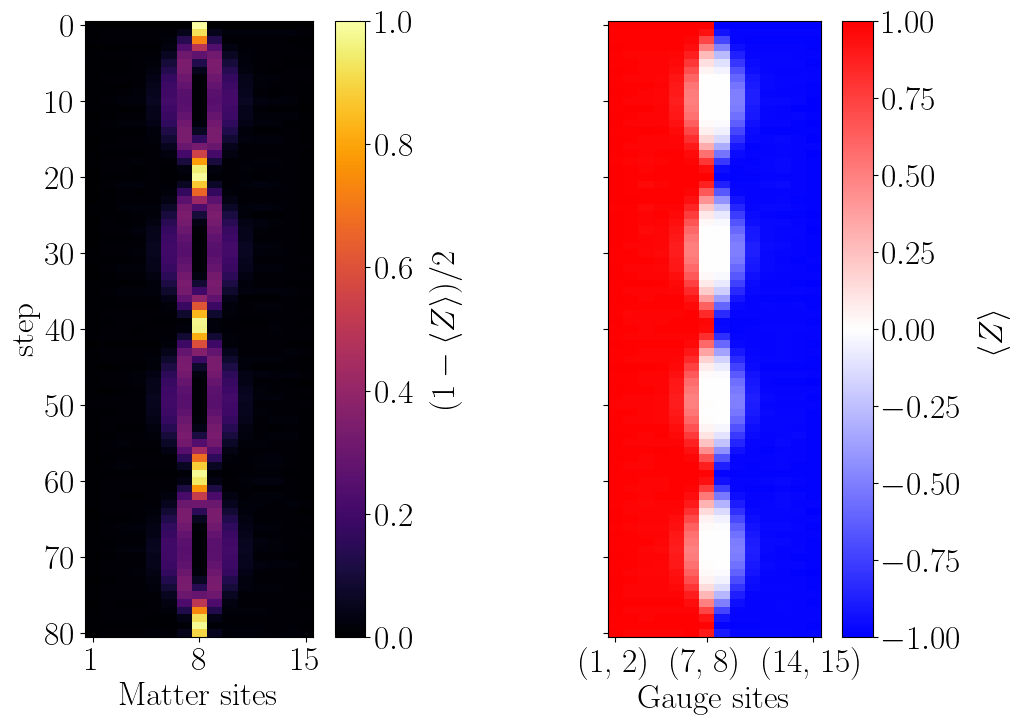

In [13]:
from z2chain.plotting import x_t_separated_plot

for i, L in enumerate(L_arr):
    for j, (J, h, lamb) in enumerate(product(J_arr, h_arr, lamb_arr)):
        x_t_separated_plot(observable_matrices[i][j], nxticks=3)

### Particle pair

Interesting set of parameters:

- Yoyo mode: $J = 5$, $h = 0.8$, $\lambda = 1$ ($t = 8$, $\mathrm{steps} = 800$, $\mathrm{plot\_each} = 10$)
- Deconfinement: $J = 5$, $h = 0.01$, $\lambda = 1$ ($t = 8$, $\mathrm{steps} = 800$, $\mathrm{plot\_each} = 10$)
- Things do not move even with low mass: $J = 0.01$, $h = 10$, $\lambda = 1$ ($t = 8$, $\mathrm{steps} = 800$, $\mathrm{plot\_each} = 10$)
- Static: $J = 20$, $h = 10$, $\lambda = 1$
- Interior yoyo (?): $J = 5$, $h = 10$, $\lambda = 1$ ($t = 8$, $\mathrm{steps} = 800$, $\mathrm{plot\_each} = 10$)
- Checkerboard delocalization: $J = 0.01$, $h = 0.5$, $\lambda = 1$ ($t = 8$, $\mathrm{steps} = 800$, $\mathrm{plot\_each} = 10$)
- Deconfined delocalization: $J = 0.5$, $h = 0.01$, $\lambda = 1$ ($t = 8$, $\mathrm{steps} = 800$, $\mathrm{plot\_each} = 10$)
- Confined delocalization: $J = 0.3$, $h = 0.8$, $\lambda = 1$ ($t = 8$, $\mathrm{steps} = 800$, $\mathrm{plot\_each} = 10$)

#### Options

In [8]:
L_arr = [21]
J_arr = [20]
h_arr = [10]
lamb_arr = [1]

x_basis = False

cutoff = 1e-8

particle_pair_left_positions = [L//2 - 3 for L in L_arr]
particle_pair_length = 6

final_time = 8
steps = 800
ploteach = 10

#### Simulation

In [9]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
from itertools import product
import numpy as np
import os

overwrite = False

observable_matrices = [] # observable_matrices[L][opts][Jhλg][t]

for i, L in enumerate(L_arr):
    this_L_observable_matrices = []
    sites = jl.chain_sites(L)
    observables = jl.all_local_pauli_z(sites)
    for J, h, lamb in product(J_arr, h_arr, lamb_arr):
        filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_steps_{steps}_L_{L}_J_{J}_h_{h:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_positions[i]}_xbasis_{x_basis}_steps_{steps}_ploteach_{ploteach}_cutoff_{cutoff}.npy"
        if os.path.exists(filepath) and not overwrite:
            this_observable_matrix = load_site_gauge_observable_matrix(filepath)
        else:
            this_observable_matrix = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, observables, J, h, lamb, particle_pair_left_positions[i], particle_pair_length, final_time, steps, x_basis, ploteach, cutoff, filepath)
            this_observable_matrix = np.array(this_observable_matrix)
            save_site_gauge_observable_matrix(this_observable_matrix, filepath)
        this_L_observable_matrices.append(this_observable_matrix)
    observable_matrices.append(this_L_observable_matrices)

t = 8.0t = 800000000153

#### Plot

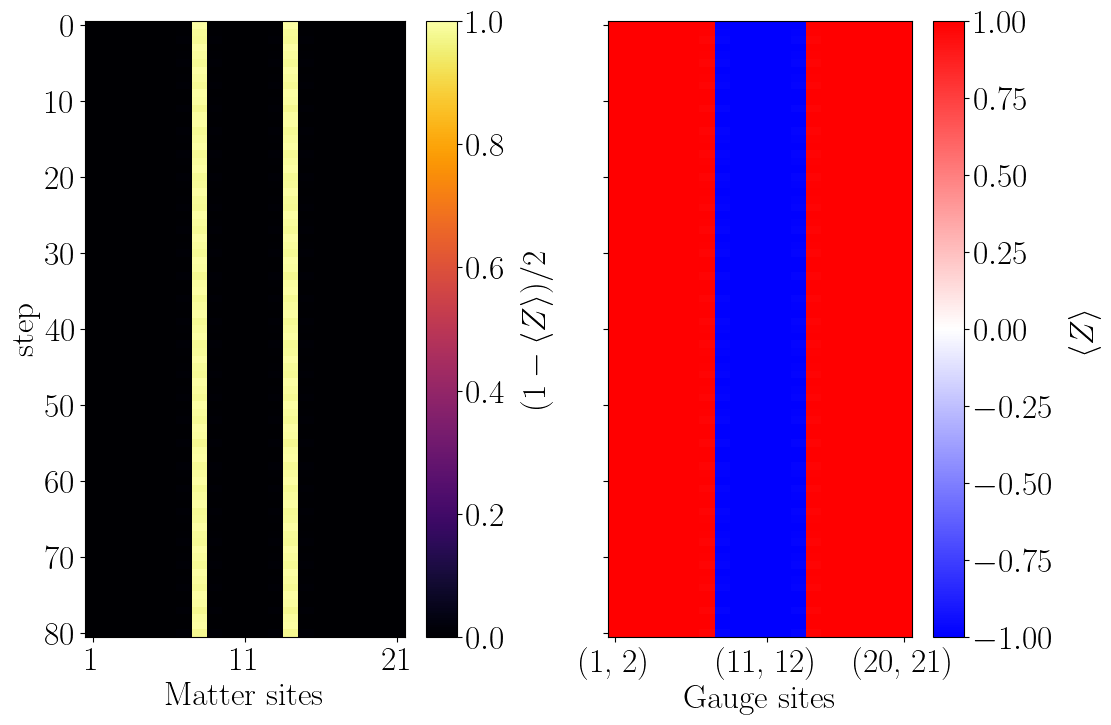

In [11]:
from z2chain.plotting import x_t_separated_plot

for i, L in enumerate(L_arr):
    for j, (J, h, lamb) in enumerate(product(J_arr, h_arr, lamb_arr)):
        x_t_separated_plot(observable_matrices[i][j], nxticks=3, filepath="static.pdf")